In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

#### ==========================================
#### 1. LOAD DATASET
#### ==========================================


In [2]:
if os.path.exists("data.csv"):

    
    df = pd.read_csv("data.csv")

    df = df[["damageDealt", "headshotKills", "killStreaks", "kills"]]
    df = df.dropna()

else:

    print("Creating sample PUBG dataset...")

    np.random.seed(42)
    n = 1000

    # Passive players
    passive = pd.DataFrame({
        "damageDealt": np.random.uniform(10, 250, n // 2),
        "headshotKills": np.random.poisson(0.2, n // 2),
        "killStreaks": np.random.choice([0, 1], n // 2, p=[0.7, 0.3]),
        "kills": np.random.choice([0, 1, 2], n // 2, p=[0.5, 0.35, 0.15])
    })

    # Aggressive players
    aggressive = pd.DataFrame({
        "damageDealt": np.random.uniform(300, 1200, n // 2),
        "headshotKills": np.random.poisson(1.8, n // 2),
        "killStreaks": np.random.choice([1, 2, 3, 4], n // 2, p=[0.2, 0.4, 0.3, 0.1]),
        "kills": np.random.randint(3, 12, n // 2)
    })

    # Combine both player groups
    df = pd.concat([passive, aggressive])

    # Shuffle the rows
    df = df.sample(frac=1, random_state=42).reset_index(drop=True)

    df["damageDealt"] = df["damageDealt"].round(2)

df["playstyle_label"] = (df["kills"] >= 3).astype(int)

print("Dataset Shape:", df.shape)
print("\nPlaystyle Distribution:")
print(df["playstyle_label"].value_counts())
print("\nFirst 5 Rows:")
print(df.head())

Dataset Shape: (1111742, 5)

Playstyle Distribution:
playstyle_label
0    982579
1    129163
Name: count, dtype: int64

First 5 Rows:
   damageDealt  headshotKills  killStreaks  kills  playstyle_label
0        25.93              0            0      0                0
1        36.71              0            0      0                0
2        47.73              0            0      0                0
3         0.00              0            0      0                0
4       100.00              0            1      1                0


In [7]:
df = df.sample(n=10000, random_state=42)

In [8]:
X = df[["damageDealt", "headshotKills", "killStreaks"]]
y = df["playstyle_label"]

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (10000, 3)
Target Shape: (10000,)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (8000, 3)
Testing Data: (2000, 3)


In [10]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature Scaling Completed!")


Feature Scaling Completed!


In [11]:
print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)

Training data: (8000, 3)
Testing data: (2000, 3)


In [12]:
knn = KNeighborsClassifier(n_neighbors=5, metric="euclidean")

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("\nKNN Accuracy:", round(accuracy * 100, 2), "%")


KNN Accuracy: 95.15 %


In [13]:
# Actual vs Predicted
comparison = pd.DataFrame({
    "Actual": y_test.values[:10],
    "Predicted": y_pred[:10]
})

print("\nActual vs Predicted:")
print(comparison)


Actual vs Predicted:
   Actual  Predicted
0       0          0
1       0          0
2       0          1
3       0          0
4       1          1
5       1          0
6       0          0
7       1          1
8       0          0
9       1          0


In [14]:
knn_minkowski = KNeighborsClassifier(
    n_neighbors=5,
    metric="minkowski",
    p=3
)

knn_manhattan = KNeighborsClassifier(
    n_neighbors=5,
    metric="manhattan"
)

knn_chebyshev = KNeighborsClassifier(
    n_neighbors=5,
    metric="chebyshev"
)

knn_hamming = KNeighborsClassifier(
    n_neighbors=5,
    metric="hamming"
)

In [15]:
models = {
    "Euclidean": knn,
    "Minkowski": knn_minkowski,
    "Manhattan": knn_manhattan,
    "Chebyshev": knn_chebyshev,
    "Hamming": knn_hamming
}

In [16]:
print("\nDISTANCE METRICS COMPARISON")

for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    prediction = model.predict(X_test_scaled)

    score = accuracy_score(y_test, prediction)

    print(name, "Accuracy:", round(score * 100, 2), "%")


DISTANCE METRICS COMPARISON
Euclidean Accuracy: 95.15 %
Minkowski Accuracy: 95.15 %
Manhattan Accuracy: 95.15 %
Chebyshev Accuracy: 95.15 %
Hamming Accuracy: 92.4 %


In [17]:
# Compare with Decision Tree
tree = DecisionTreeClassifier(random_state=42)

tree.fit(X_train_scaled, y_train)

tree_pred = tree.predict(X_test_scaled)

tree_accuracy = accuracy_score(y_test, tree_pred)

print("Decision Tree Accuracy:", round(tree_accuracy * 100, 2), "%")


Decision Tree Accuracy: 94.55 %


In [18]:

# ==========================================
# PREDICT A NEW PLAYER
# ==========================================

new_player = [[650.0, 2, 2]]

new_player_scaled = scaler.transform(new_player)

prediction = knn.predict(new_player_scaled)

probability = knn.predict_proba(new_player_scaled)

if prediction[0] == 1:
    print("\nPredicted Playstyle: Aggressive Fragger")
else:
    print("\nPredicted Playstyle: Passive / Stealth Looter")

print("Confidence:", round(probability[0][prediction[0]] * 100, 1), "%")



Predicted Playstyle: Aggressive Fragger
Confidence: 100.0 %


C:\Users\kkelu\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [19]:
# Test another player
new_player = [[85.0, 0, 0]]

new_player_scaled = scaler.transform(new_player)

prediction = knn.predict(new_player_scaled)

if prediction[0] == 1:
    print("\nPredicted Playstyle: Aggressive Fragger")
else:
    print("\nPredicted Playstyle: Passive / Stealth Looter")

probability = knn.predict_proba(new_player_scaled)
print("Confidence:", round(probability[0][prediction[0]] * 100, 1), "%")



Predicted Playstyle: Passive / Stealth Looter
Confidence: 100.0 %


C:\Users\kkelu\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


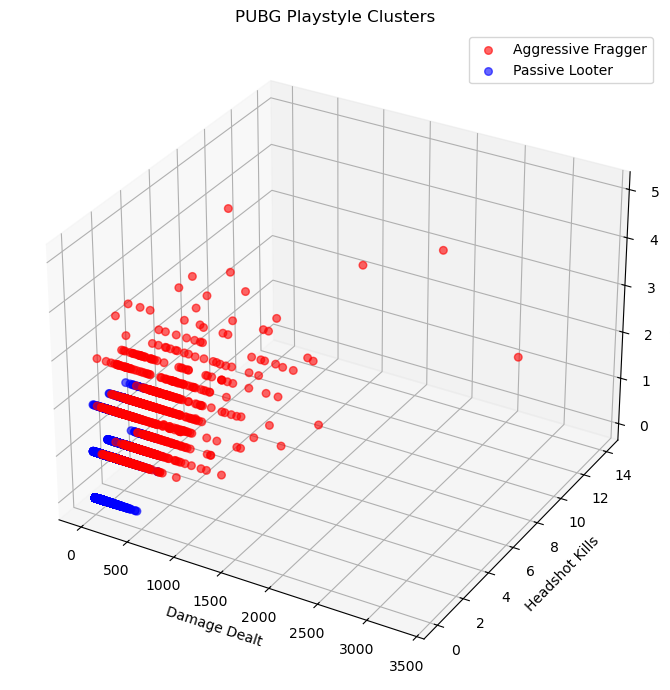

In [21]:
aggressive = df[df["playstyle_label"] == 1]
passive = df[df["playstyle_label"] == 0]

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    aggressive["damageDealt"],
    aggressive["headshotKills"],
    aggressive["killStreaks"],
    color="red",
    label="Aggressive Fragger",
    alpha=0.6,
    s=30
)

ax.scatter(
    passive["damageDealt"],
    passive["headshotKills"],
    passive["killStreaks"],
    color="blue",
    label="Passive Looter",
    alpha=0.6,
    s=30
)

ax.set_title("PUBG Playstyle Clusters")
ax.set_xlabel("Damage Dealt")
ax.set_ylabel("Headshot Kills")
ax.set_zlabel("Kill Streaks")

ax.legend()
plt.tight_layout()

plt.savefig("pubg_playstyle_3d_cluster.png", dpi=150)
plt.show()


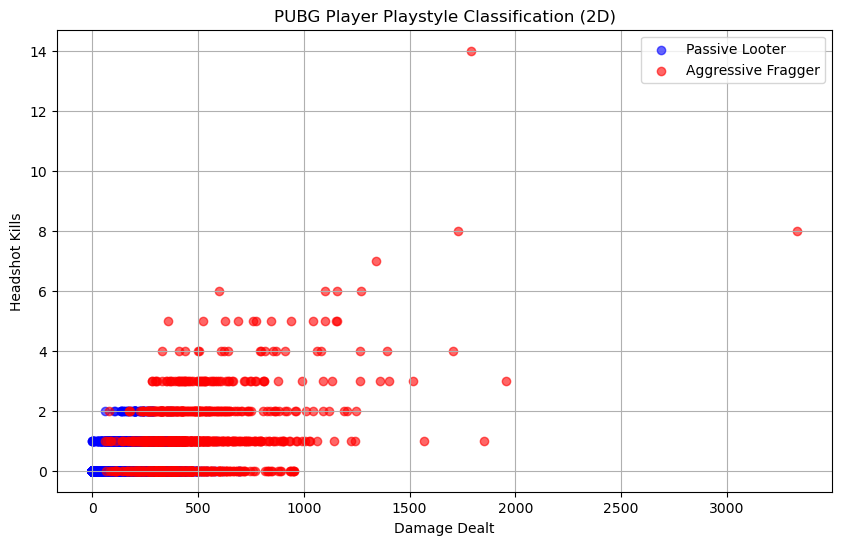

In [22]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df[df['playstyle_label'] == 0]['damageDealt'],
    df[df['playstyle_label'] == 0]['headshotKills'],
    color='blue',
    label='Passive Looter',
    alpha=0.6
)

plt.scatter(
    df[df['playstyle_label'] == 1]['damageDealt'],
    df[df['playstyle_label'] == 1]['headshotKills'],
    color='red',
    label='Aggressive Fragger',
    alpha=0.6
)

plt.xlabel('Damage Dealt')
plt.ylabel('Headshot Kills')
plt.title('PUBG Player Playstyle Classification (2D)')
plt.legend()
plt.grid(True)

plt.savefig('pubg_playstyle_2d.png', dpi=150)
plt.show()